# Part 2 — Pre-Inference EDA & Readiness

## Scope: justify preprocessing BEFORE OCR/model execution

Audit **all 3,083 official annotated images**, preserving train/test and unmatched records, from existing integrated Products/Images/Annotations. Product metadata is available for the 3,075 barcode matches, not a packaging-verified reference. **No model predictions, F1 scores, OCR runs or LayoutLM forward passes are used.** The local fast tokenizer only measures subword lengths; no model weights are opened or downloaded.

Pixel analysis uses **all identifiable locally cached original Part 2 images only**. This availability/convenience sample is not random or representative. Uncached images remain explicitly unmeasured; metadata/annotation diagnostics still cover all records. No original image, OCR token, box, gold label, prior notebook or model implementation is modified.

Required validation/alignment and model-length operations are separated from optional image enhancements, annotation-quality review, and post-inference numerical validation. Heuristic quality flags are not calibrated accuracy labels. Aspect ratio cannot determine text rotation, and an OCR bounding envelope is not a nutrition-table crop annotation.

In [7]:
from pathlib import Path
import sys
import json
import importlib
import pandas as pd
from IPython.display import display, Markdown, Image as DisplayImage
ROOT = Path.cwd().resolve()
if not (ROOT / 'app.py').exists() and (ROOT / 'nutrition_extraction_solution/app.py').exists():
    ROOT = ROOT / 'nutrition_extraction_solution'
for path in [ROOT, ROOT / 'src']:
    if str(path) not in sys.path:
        sys.path.insert(0, str(path))
import scripts.preprocessing_readiness as readiness
readiness = importlib.reload(readiness)
OUTPUT = ROOT / 'outputs/preprocessing_readiness'
manifest, tables, recommendations = readiness.run(ROOT, OUTPUT)
print(json.dumps({key: value for key, value in manifest.items() if key not in ['source_sha256','tokenizer_assets']}, indent=2))
display(recommendations)
assert manifest['total_annotated_images'] == 3083
assert manifest['matched_products'] == 3075 and manifest['unmatched_images'] == 8
assert manifest['prediction_caches_read'] == manifest['model_inference_runs'] == manifest['ocr_runs'] == 0

{
  "version": "1.0",
  "generated_at_utc": "2026-10-30T12:47:57.436322+00:00",
  "total_annotated_images": 3083,
  "matched_products": 3075,
  "unmatched_images": 8,
  "split_counts": {
    "test": 199,
    "train": 2884
  },
  "token_annotations": 309190,
  "pixel_measured_images": 25,
  "cached_unreadable_images": 0,
  "pixel_sampling": "All locally cached original Part2 images identifiable using the existing dataset loader cache hash. Availability/convenience sample, NOT random or representative. No uncached images downloaded.",
  "measured_pixel_split_counts": {
    "test": 23,
    "train": 2
  },
  "tokenizer_measured_images": 3083,
  "sliding_window_images": 455,
  "rules": {
    "short_side_review_px": 400,
    "dark_mean_gray": 60,
    "bright_mean_gray": 220,
    "low_gray_std": 30,
    "low_laplacian_variance": 100,
    "laplacian_measure_max_side": 1000,
    "high_box_iou": 0.8,
    "large_margin_ocr_envelope_fraction": 0.4
  },
  "proxy_experiment_images": 8,
  "measured_i

,observed_issue,affected_count,denominator,affected_percent,denominator_scope,decision_class,preprocessing_required,expected_benefit,validation_method
0,Input longer than 512 LayoutLMv3 subwords incl...,455,3083,14.758352,tokenizer-measured annotated images,Required preprocessing,Retain existing overlapping sliding windows an...,Full original-word coverage rather than silent...,Assert every original word is covered; validat...
1,Invalid/alignment-risk token-box-label records,47,3083,1.524489,all annotated images,Required preprocessing,"Validate aligned tokens/boxes/labels and [0,10...",Prevent invalid model inputs while preserving ...,"Read-only alignment, coordinate and tokenizer ..."
2,EXIF orientation transformation indicated,0,25,0.000000,cached pixel-measured images only,Required preprocessing,Retain EXIF-aware image loading for new OCR in...,Avoid metadata-directed orientation mismatch.,Compare original/oriented dimensions and trans...
3,Short image side below 400 pixels,327,3083,10.606552,all images with source dimensions,Data-quality review flag,Inspect legibility; do not assume upscaling re...,Identify likely text-detail limitations before...,Inspect representative panels and validate OCR...
4,Source maximum side exceeds existing 2000px OC...,541,3083,17.547843,all images with source dimensions,Optional preprocessing,Retain aspect-preserving maximum-side resize a...,Bound CPU OCR workload while avoiding unnecess...,Compare before/after legibility and manual-ref...
5,Low grayscale contrast proxy,3,25,12.000000,cached pixel-measured convenience sample only,Optional preprocessing,Consider contrast normalization only on review...,Potential readability benefit is a hypothesis;...,Paired before/after OCR on manually transcribe...
6,Low sharpness/Laplacian proxy,0,25,0.000000,cached pixel-measured convenience sample only,Optional preprocessing,Review small/blurred panels; do not apply unco...,Potential readability benefit is a hypothesis;...,Paired before/after OCR on manually transcribe...
7,Dark luminance proxy,1,25,4.000000,cached pixel-measured convenience sample only,Optional preprocessing,Consider brightness correction only if visual ...,Potential readability benefit is a hypothesis;...,Paired before/after OCR on manually transcribe...
8,Bright luminance proxy,0,25,0.000000,cached pixel-measured convenience sample only,Optional preprocessing,Review white-background versus overexposure; a...,Potential readability benefit is a hypothesis;...,Paired before/after OCR on manually transcribe...
9,Small OCR envelope within image (<40% of norma...,96,3083,3.113850,all annotated images with valid boxes,Data-quality review flag,Inspect candidate margins; do not auto-crop fr...,Potentially reduce irrelevant packaging text w...,Manually verify crop retains every target span...


## 1. Image quality and sampling

Source dimensions/aspect ratios are inspected on all images. Pixel brightness, contrast, blur proxy, mode and EXIF are measured only on cached originals. Pixel sample is availability-based, test-heavy and not representative. Luminance uses grayscale mean/std; sharpness uses Laplacian variance at max-side 1000px without upscaling. Thresholds (short side <400px, grayscale mean <60 or >220, std <30, Laplacian variance <100) are explicit review heuristics, not validated OCR-quality classifiers.

A small OCR envelope (<40% of normalized image area) is a margin-review hypothesis, not a crop instruction. Aspect ratio cannot detect rotated text. No cropping, deskew, rotation, thresholding or enhancement is automatically applied to originals.

,split,match_status,images,short_side_review,crop_margin_review
0,test,barcode_matched_image_unverified,199,25,6
1,train,barcode_matched_image_unverified,2876,299,90
2,train,barcode_unmatched,8,3,0


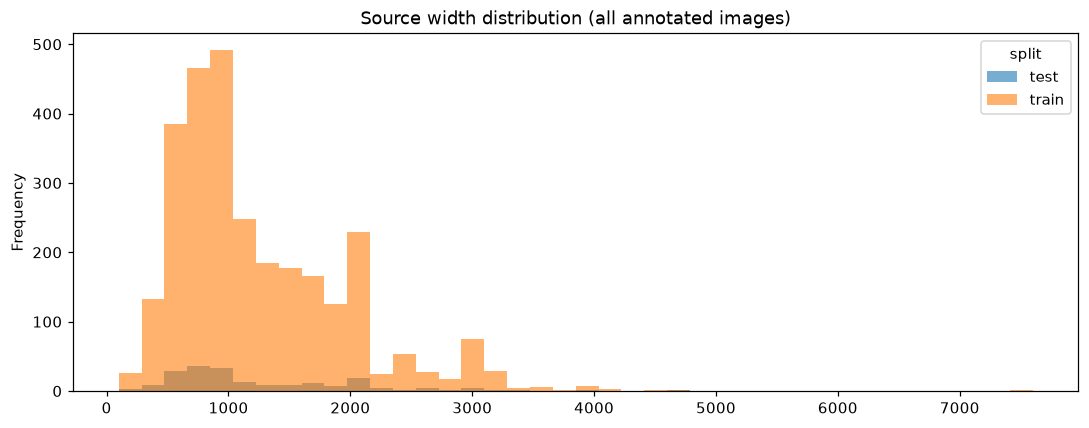

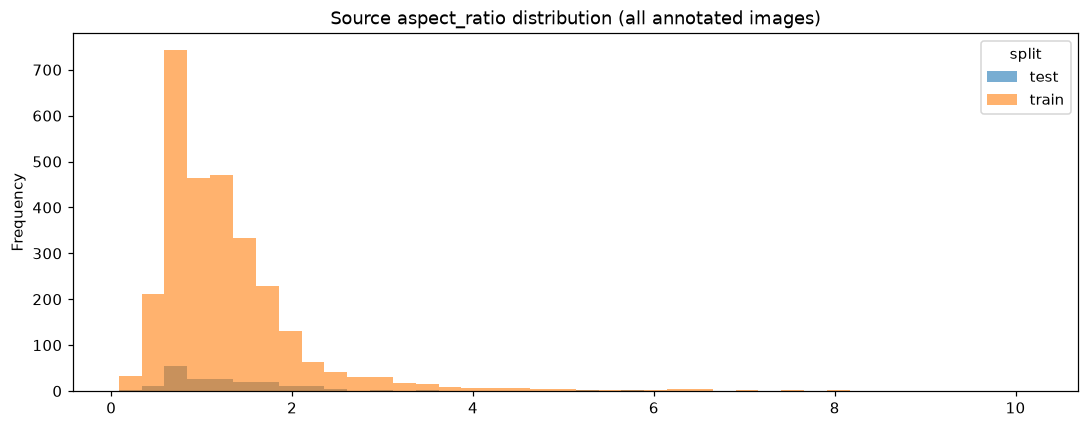

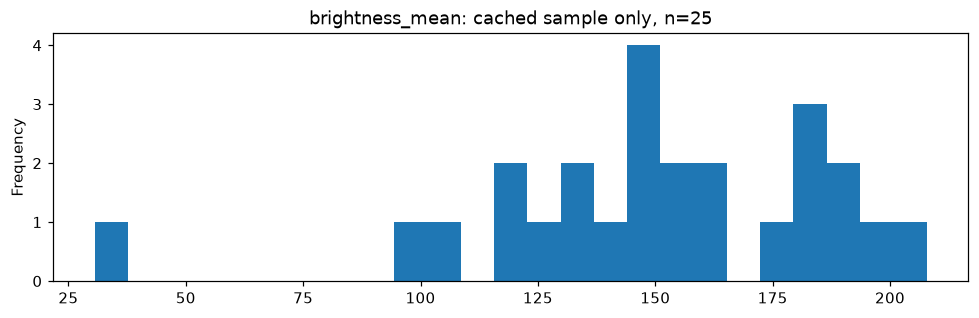

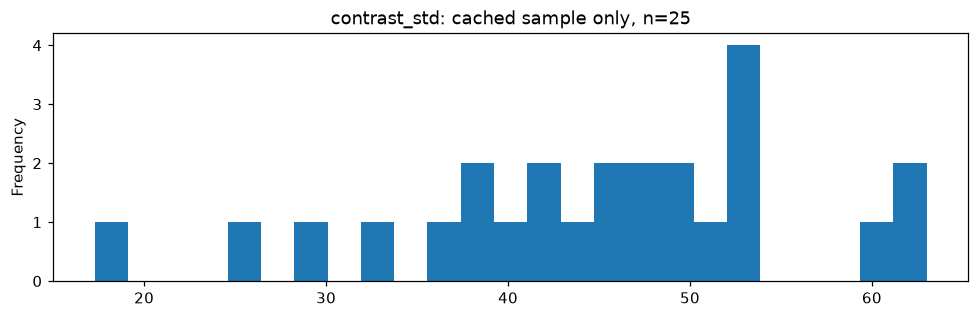

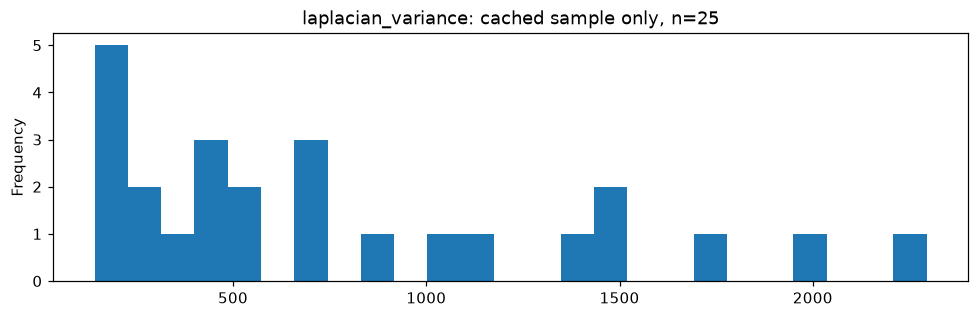

,image_key,split,brightness_mean,contrast_std,laplacian_variance,exif_orientation,quality_flags
0,train:0,train,162.805867,63.000370,1972.203603,1.0,
1,train:1,train,128.401468,41.830063,163.904657,1.0,
2884,test:0,test,145.238651,49.843033,459.121380,1.0,ocr_envelope_small_crop_review_not_table_local...
2885,test:1,test,181.072974,28.525286,320.186788,1.0,low_contrast_proxy
2886,test:2,test,158.863831,46.055075,1729.691756,1.0,short_side_lt400_review
2890,test:6,test,94.617179,60.854322,255.392178,1.0,ocr_envelope_small_crop_review_not_table_local...
2891,test:7,test,135.923110,46.756024,154.529630,1.0,
2892,test:8,test,146.730844,50.676285,2294.157567,1.0,
2906,test:22,test,180.654600,40.755036,905.341899,1.0,
2907,test:23,test,154.056205,24.763075,293.986381,1.0,low_contrast_proxy


Pixel sampling: All locally cached original Part2 images identifiable using the existing dataset loader cache hash. Availability/convenience sample, NOT random or representative. No uncached images downloaded.


In [9]:
import matplotlib
matplotlib.use('Agg', force=True)
import matplotlib.pyplot as plt
FIGURES = OUTPUT / 'figures'
FIGURES.mkdir(exist_ok=True)
def save_plot(name):
    path = FIGURES / name
    plt.tight_layout()
    plt.savefig(path, dpi=110, bbox_inches='tight')
    plt.close('all')
    display(DisplayImage(filename=str(path)))
images = tables['images']
pixels = images.loc[images['pixel_status'].eq('measured_cached_original')]
display(images.groupby(['split','match_status']).agg(images=('image_key','size'), short_side_review=('short_side_review','sum'), crop_margin_review=('large_margin_crop_review','sum')).reset_index())
for field in ['width', 'aspect_ratio']:
    images.pivot(columns='split', values=field).plot.hist(alpha=.6, bins=40, figsize=(10,4), title=f'Source {field} distribution (all annotated images)')
    save_plot(f'image_{field}.png')
for field in ['brightness_mean','contrast_std','laplacian_variance']:
    if not pixels.empty:
        pixels[field].plot.hist(bins=25, figsize=(9,3), title=f'{field}: cached sample only, n={len(pixels)}')
        save_plot(f'pixel_{field}.png')
display(pixels[['image_key','split','brightness_mean','contrast_std','laplacian_variance','exif_orientation','quality_flags']])
print('Pixel sampling:', manifest['pixel_sampling'])

## 2. OCR text, geometry and exact tokenizer lengths

Supplied OCR diagnostics include decimal commas/points, merged number-unit strings, multiple numeric mentions, glyph/separator anomalies, long tokens and backward y-jumps. These are measurable segmentation risks, not independent OCR error labels. Preserve original corpus word order and geometry; numerical normalization belongs in a reversible parser, never a gold-text rewrite.

Boxes are checked for integer `[0,1000]` coordinates, positive area, duplicates, high IoU, original index continuity and token/box/tag alignment. Successful local tokenizer length measurement **does not approve box geometry**. Fast-tokenizer lengths are measured untruncated with special tokens and raw boxes; >512 text positions indicates a need for existing sliding windows. We do not run the model or measure extraction performance here.

,issue,affected_images,denominator,percent,occurrences
0,decimal_comma_tokens,2463,3083,79.889718,15816
1,decimal_point_tokens,1152,3083,37.366202,4489
2,merged_number_unit_tokens,2565,3083,83.198184,14125
3,multiple_numeric_tokens,890,3083,28.867986,1549
4,malformed_numeric_review_tokens,386,3083,12.520272,580
5,long_tokens,151,3083,4.897827,306
6,backward_y_jumps,2825,3083,91.631528,15831
7,invalid_box_count,0,3083,0.000000,0
8,out_of_range_box_count,0,3083,0.000000,0
9,zero_area_boxes,47,3083,1.524489,69


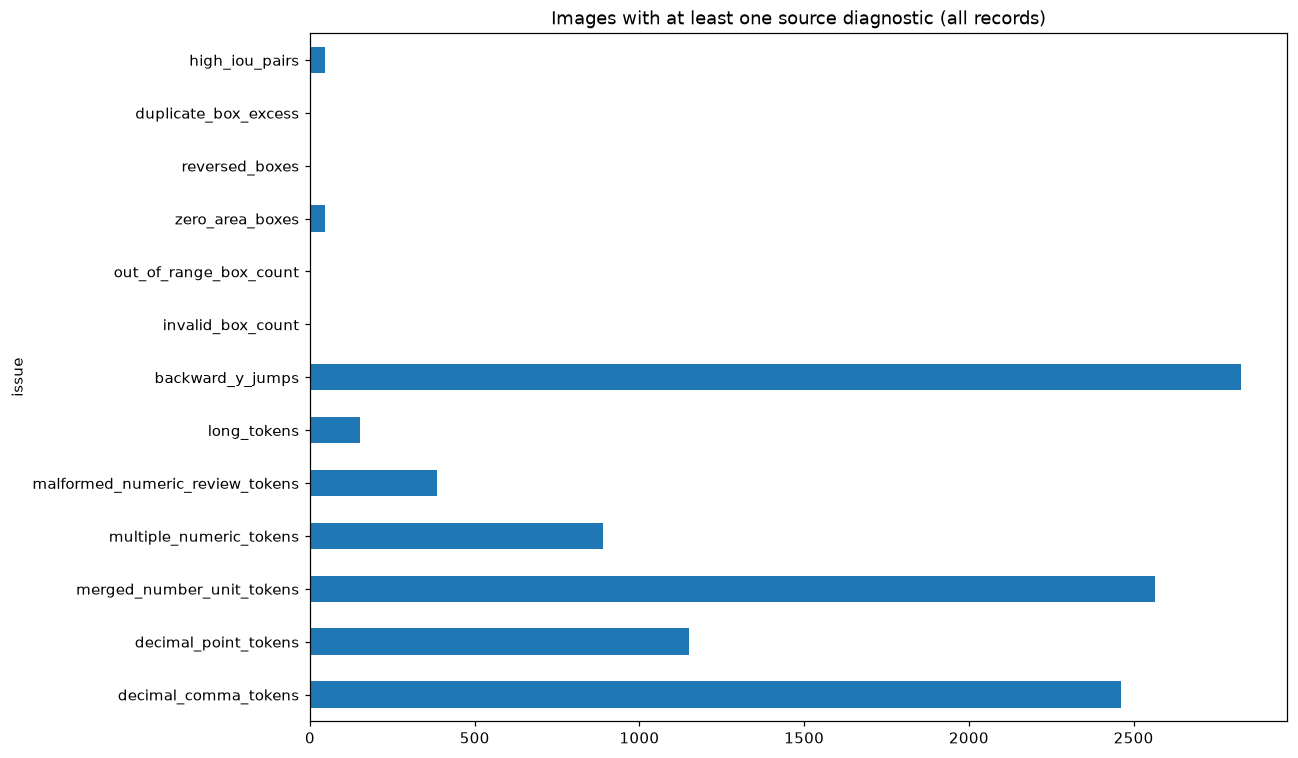

,image_key,barcode,split,token_index,ocr_token,issue
0,train:0,3831051012073,train,1,og,numeric_glyph_or_separator_review
1,train:0,3831051012073,train,69,13g,number_unit_in_same_OCR_token
2,train:0,3831051012073,train,94,og,numeric_glyph_or_separator_review
3,train:0,3831051012073,train,106,"5,1g",number_unit_in_same_OCR_token
4,train:0,3831051012073,train,107,"5,1g\n",number_unit_in_same_OCR_token
5,train:0,3831051012073,train,108,40g\n,number_unit_in_same_OCR_token
6,train:0,3831051012073,train,109,"0,11g\n",number_unit_in_same_OCR_token
7,train:1,0059441001350,train,45,0g,number_unit_in_same_OCR_token
8,train:3,4100910005426,train,3,100ml,number_unit_in_same_OCR_token
9,train:3,4100910005426,train,8,100ml\n,number_unit_in_same_OCR_token


,image_key,barcode,token_box_alignment,invalid_box_indices,zero_area_boxes,reversed_boxes,out_of_range_box_count
214,train:214,3280316028739,True,[125],1,0,0
360,train:360,8008910153092,True,"[158, 212, 265]",3,0,0
367,train:367,5449000164049,True,[11],1,0,0
399,train:399,3596710432486,True,"[273, 321]",2,0,0
539,train:539,7613312010761,True,"[37, 115, 488, 510]",4,0,0
559,train:559,3664335003333,True,[41],1,0,0
575,train:575,0877974001025,True,[86],1,0,0
605,train:605,3497720006271,True,"[58, 73]",2,0,0
805,train:805,3760211820688,True,[137],1,0,0
894,train:894,0016229000592,True,[76],1,0,0


Tokenizer measured images: 3083 Longer than512: 455


,split,match_status,images,sliding_window,max_subwords,missed_words_single_pass
0,test,barcode_matched_image_unverified,199,32,3495,3679
1,train,barcode_matched_image_unverified,2876,422,2758,42191
2,train,barcode_unmatched,8,1,514,1


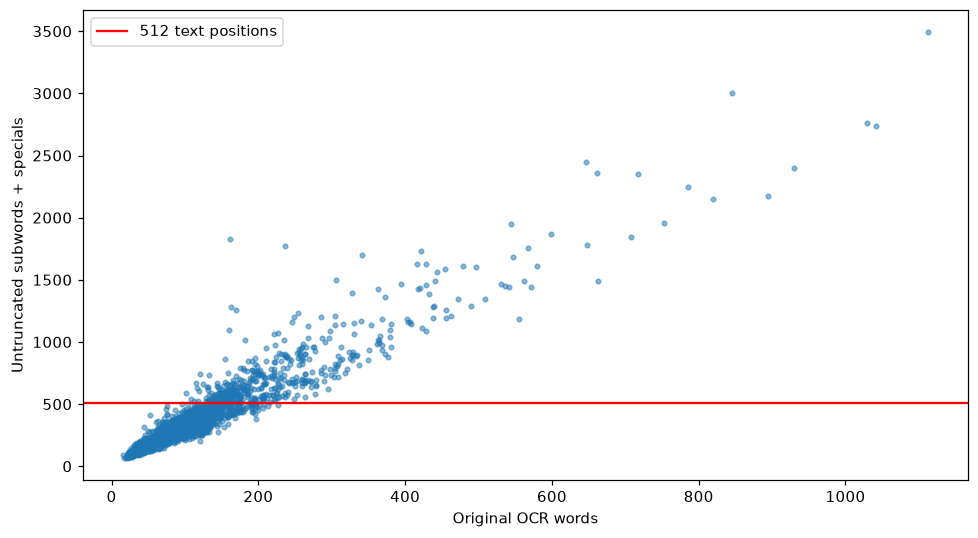

In [10]:
diagnostics = ['decimal_comma_tokens','decimal_point_tokens','merged_number_unit_tokens','multiple_numeric_tokens','malformed_numeric_review_tokens','long_tokens','backward_y_jumps','invalid_box_count','out_of_range_box_count','zero_area_boxes','reversed_boxes','duplicate_box_excess','high_iou_pairs']
affected = pd.DataFrame([{'issue':name,'affected_images':int(images[name].gt(0).sum()),'denominator':len(images),'percent':float(images[name].gt(0).mean()*100),'occurrences':int(images[name].sum())} for name in diagnostics])
display(affected)
affected.set_index('issue')['affected_images'].plot.barh(figsize=(12,7), title='Images with at least one source diagnostic (all records)')
save_plot('text_geometry_diagnostics.png')
display(tables['token_examples'].head(40))
display(images.loc[images[['invalid_box_count','out_of_range_box_count','zero_area_boxes','reversed_boxes']].gt(0).any(axis=1), ['image_key','barcode','token_box_alignment','invalid_box_indices','zero_area_boxes','reversed_boxes','out_of_range_box_count']])
measured_lengths = images.loc[images['subword_tokens_with_specials'].notna()]
print('Tokenizer measured images:', len(measured_lengths), 'Longer than512:', int(measured_lengths['needs_sliding_window'].sum()))
display(measured_lengths.groupby(['split','match_status']).agg(images=('image_key','size'), sliding_window=('needs_sliding_window','sum'), max_subwords=('subword_tokens_with_specials','max'), missed_words_single_pass=('words_missed_by_single_pass','sum')).reset_index())
plt.figure(figsize=(9,5))
plt.scatter(measured_lengths['token_count'], measured_lengths['subword_tokens_with_specials'], s=9, alpha=.5)
plt.axhline(512, color='red', label='512 text positions')
plt.xlabel('Original OCR words')
plt.ylabel('Untruncated subwords + specials')
plt.legend()
save_plot('subword_length_risk.png')

## 3. Gold annotation integrity, unit/basis metadata and dataset differences

Inspect label frequencies, entity counts, multiword spans, invalid I- continuations and basis distribution without repairing labels. Gold labels diagnose annotation readiness only and are not features for OCR on unseen images. Compare the original train/test distributions and tiny unmatched cohort to disclose potential selection bias.

Product metadata uses source mass/energy field conventions, **not packaging-verified units or image truth**. Missing serving mass prevents unsupported per-serving conversion. Negative/implausible database values are downstream review flags, not a justification to change image preprocessing or evaluation gold.

split,test,train
label,,
B-ADDED_SUGARS_100G,0,2
B-ADDED_SUGARS_SERVING,3,64
B-CALCIUM_100G,5,72
B-CALCIUM_SERVING,3,85
B-CARBOHYDRATES_100G,187,2672
...,...,...
I-TRANS_FAT_100G,0,12
I-TRANS_FAT_SERVING,1,47
I-VITAMIN_D_100G,1,17


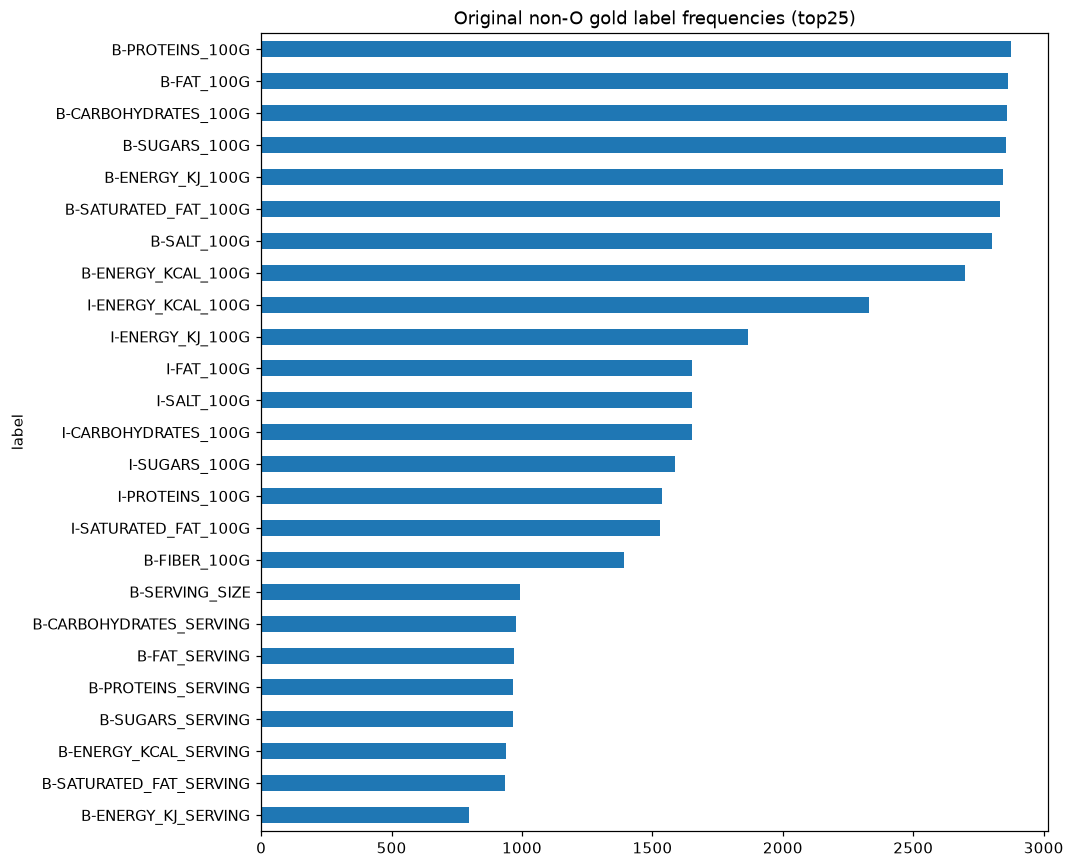

,split,match_status,images,mean_tokens,median_subwords,entities,multi_token_entities,per_100g,per_serving,bio_review
0,test,barcode_matched_image_unverified,199,110.854271,249.0,2291,1383,1586,634,0
1,train,barcode_matched_image_unverified,2876,99.609875,243.5,31773,18548,22627,8229,0
2,train,barcode_unmatched,8,81.500000,227.0,102,57,70,29,0


,image_key,barcode,split,token_index,label,issue


,match_status,nutrient,source_unit_convention,products,finite_values,serving_size_available,packaging_unit_verified
0,barcode_matched_image_unverified,calcium,g,3075,527,736,0
1,barcode_matched_image_unverified,carbohydrates,g,3075,3067,736,0
2,barcode_matched_image_unverified,energy_kcal,kcal,3075,3063,736,0
3,barcode_matched_image_unverified,energy_kj,kj,3075,2938,736,0
4,barcode_matched_image_unverified,fat,g,3075,3068,736,0
5,barcode_matched_image_unverified,fiber,g,3075,1201,736,0
6,barcode_matched_image_unverified,iron,g,3075,528,736,0
7,barcode_matched_image_unverified,potassium,g,3075,482,736,0
8,barcode_matched_image_unverified,proteins,g,3075,3066,736,0
9,barcode_matched_image_unverified,salt,g,3075,2897,736,0


,barcode,match_status,nutrient,source_field,source_unit_convention,basis_convention,raw_value,numeric_value,finite_numeric,review_flag,unit_verified_from_packaging,serving_size,serving_size_available,serving_mass_or_volume_parseable
198,0010749008274,barcode_matched_image_unverified,carbohydrates,carbohydrates_100g,g,per_100g,149,1.490000e+02,True,unit_or_basis_implausible_quantity_review,False,41g,True,True
210,0011110004925,barcode_matched_image_unverified,fat,fat_100g,g,per_100g,130,1.300000e+02,True,unit_or_basis_implausible_quantity_review,False,34g,True,True
364,0011110724168,barcode_matched_image_unverified,fat,fat_100g,g,per_100g,156,1.560000e+02,True,unit_or_basis_implausible_quantity_review,False,30g,True,True
372,0011110724168,barcode_matched_image_unverified,energy_kcal,energy-kcal_100g,kcal,per_100g,1930,1.930000e+03,True,unit_or_basis_implausible_quantity_review,False,30g,True,True
627,0013256220412,barcode_matched_image_unverified,iron,iron_100g,g,per_100g,1000,1.000000e+03,True,unit_or_basis_implausible_quantity_review,False,,False,False
628,0013256220412,barcode_matched_image_unverified,potassium,potassium_100g,g,per_100g,600,6.000000e+02,True,unit_or_basis_implausible_quantity_review,False,,False,False
708,0014100074816,barcode_matched_image_unverified,energy_kcal,energy-kcal_100g,kcal,per_100g,1625,1.625000e+03,True,unit_or_basis_implausible_quantity_review,False,2 cookies (25 g),True,True
814,0015839000022,barcode_matched_image_unverified,carbohydrates,carbohydrates_100g,g,per_100g,227,2.270000e+02,True,unit_or_basis_implausible_quantity_review,False,28.3495g,True,True
820,0015839000022,barcode_matched_image_unverified,energy_kcal,energy-kcal_100g,kcal,per_100g,1800,1.800000e+03,True,unit_or_basis_implausible_quantity_review,False,28.3495g,True,True
828,0015878012512,barcode_matched_image_unverified,carbohydrates,carbohydrates_100g,g,per_100g,256,2.560000e+02,True,unit_or_basis_implausible_quantity_review,False,30g,True,True


No per-serving quantity was converted without explicit serving context; no database value was substituted for gold.


In [5]:
support = tables['label_counts'].groupby(['label','split'])['count'].sum().unstack(fill_value=0)
display(support)
support.loc[support.index!='O'].sum(axis=1).nlargest(25).sort_values().plot.barh(figsize=(10,8), title='Original non-O gold label frequencies (top25)')
save_plot('gold_labels.png')
display(images.groupby(['split','match_status']).agg(images=('image_key','size'),mean_tokens=('token_count','mean'),median_subwords=('subword_tokens_with_specials','median'),entities=('entity_count','sum'),multi_token_entities=('multi_token_entities','sum'),per_100g=('per_100g_entities','sum'),per_serving=('per_serving_entities','sum'),bio_review=('invalid_bio_transitions','sum')).reset_index())
display(tables['bio_transition_examples'])
metadata = tables['metadata']
display(metadata.groupby(['match_status','nutrient','source_unit_convention']).agg(products=('barcode','nunique'), finite_values=('finite_numeric','sum'), serving_size_available=('serving_size_available','sum'),packaging_unit_verified=('unit_verified_from_packaging','sum')).reset_index())
display(metadata.loc[metadata['review_flag'].ne('')])
print('No per-serving quantity was converted without explicit serving context; no database value was substituted for gold.')

## 4. Representative originals and preprocessing-copy experiment

Use at most eight already cached originals to test the **existing** `max_side=2000, contrast=1.15` adapter on in-memory copies saved only under this audit's output folder. Inspect measured brightness/contrast/sharpness before/after. This is a feasibility/proxy comparison, **not an OCR quality comparison**. No sample-matched independent transcription is available for these annotated corpus images, so CER/WER improvement is not established and no blanket enhancement is recommended. Future adoption requires a controlled paired OCR run on independently transcribed images, preserving splits and identical OCR settings.

Even when an image is flagged, expected benefit is a hypothesis; current recommendations distinguish required validation/windowing from optional enhancement and data-quality review.

,image_key,barcode,transformation,before_brightness,after_brightness,before_contrast,after_contrast,before_sharpness,after_sharpness,original_width,original_height,transformed_width,transformed_height,original_path,transformed_path,ocr_quality_before,ocr_quality_after,conclusion
0,test:0,3700821000223,existing max_side=2000 + contrast=1.15 on a CO...,145.238651,144.895033,49.843033,56.841115,459.121380,555.195069,771.0,890.0,771,890,C:\Users\SaniaJawaid\Documents\projects\practi...,C:\Users\SaniaJawaid\Documents\projects\practi...,None,None,Pixel proxies only; no evidence of improved OC...
1,test:1,06174988,existing max_side=2000 + contrast=1.15 on a CO...,181.072974,180.534479,28.525286,32.679350,320.186788,414.021530,611.0,702.0,611,702,C:\Users\SaniaJawaid\Documents\projects\practi...,C:\Users\SaniaJawaid\Documents\projects\practi...,None,None,Pixel proxies only; no evidence of improved OC...
2,test:108,5400141358339,existing max_side=2000 + contrast=1.15 on a CO...,145.054594,145.401872,61.481635,68.601363,1499.057234,1860.097300,1080.0,849.0,1080,849,C:\Users\SaniaJawaid\Documents\projects\practi...,C:\Users\SaniaJawaid\Documents\projects\practi...,None,None,Pixel proxies only; no evidence of improved OC...
3,test:139,4099100042832,existing max_side=2000 + contrast=1.15 on a CO...,116.621113,116.202342,52.368391,60.073224,407.172563,536.649086,702.0,1200.0,702,1200,C:\Users\SaniaJawaid\Documents\projects\practi...,C:\Users\SaniaJawaid\Documents\projects\practi...,None,None,Pixel proxies only; no evidence of improved OC...
4,test:151,7610818170104,existing max_side=2000 + contrast=1.15 on a CO...,103.954771,103.156127,52.725856,59.591404,426.999422,559.779973,1601.0,1200.0,1601,1200,C:\Users\SaniaJawaid\Documents\projects\practi...,C:\Users\SaniaJawaid\Documents\projects\practi...,None,None,Pixel proxies only; no evidence of improved OC...
5,test:163,4316268451086,existing max_side=2000 + contrast=1.15 on a CO...,138.242343,137.826218,33.480648,38.505946,158.629583,209.717051,843.0,1200.0,843,1200,C:\Users\SaniaJawaid\Documents\projects\practi...,C:\Users\SaniaJawaid\Documents\projects\practi...,None,None,Pixel proxies only; no evidence of improved OC...
6,test:173,7613036278621,existing max_side=2000 + contrast=1.15 on a CO...,134.185923,133.785881,38.723962,44.567093,531.798346,709.834381,3120.0,606.0,2000,388,C:\Users\SaniaJawaid\Documents\projects\practi...,C:\Users\SaniaJawaid\Documents\projects\practi...,None,None,Pixel proxies only; no evidence of improved OC...
7,test:188,3073781131925,existing max_side=2000 + contrast=1.15 on a CO...,192.211845,191.829155,37.790703,43.249821,1423.711616,1850.032803,1249.0,420.0,1249,420,C:\Users\SaniaJawaid\Documents\projects\practi...,C:\Users\SaniaJawaid\Documents\projects\practi...,None,None,Pixel proxies only; no evidence of improved OC...


test:57 3661945710026 short_side_lt400_review|dark_luminance_review|low_contrast_proxy


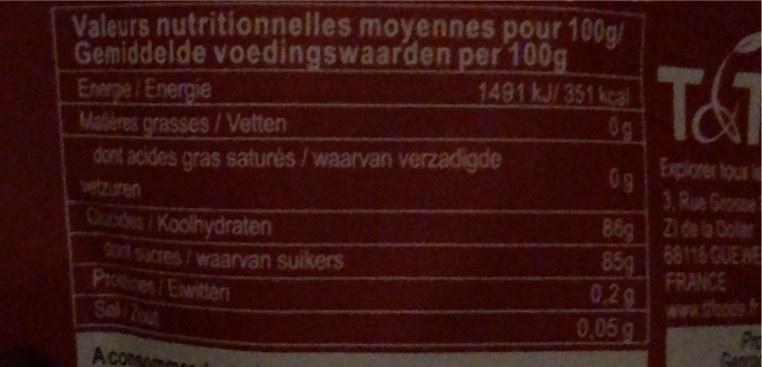

test:2 7613379505774 short_side_lt400_review


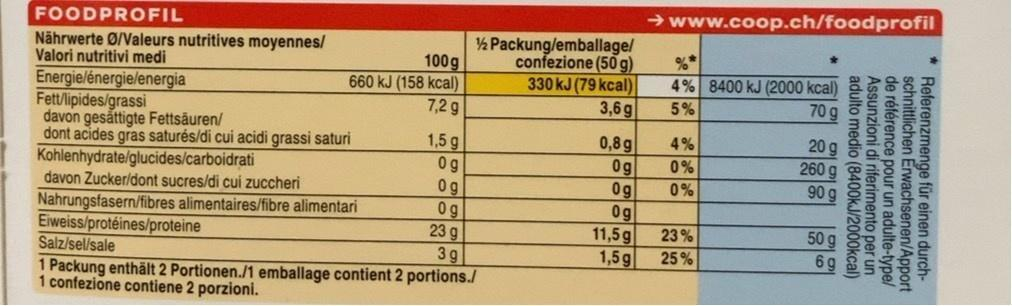

test:55 3383810002646 short_side_lt400_review


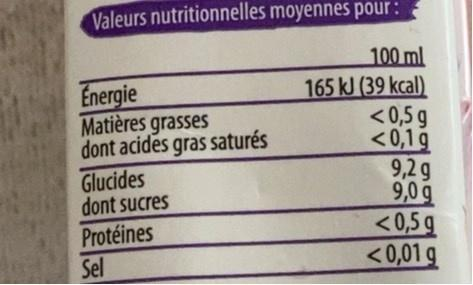

test:59 6141437686062 short_side_lt400_review


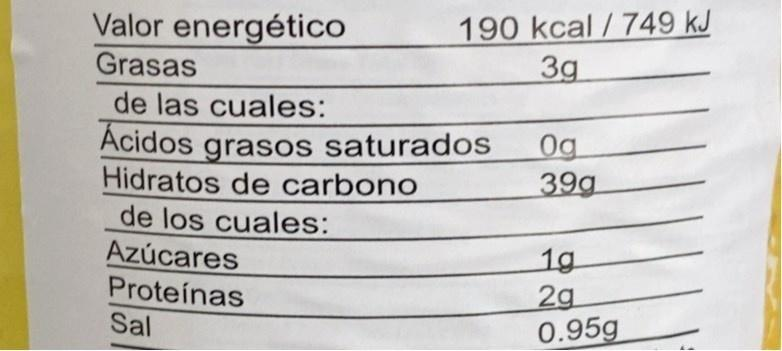

test:0 Pixel proxies only; no evidence of improved OCR accuracy. Need matched manual transcription and controlled OCR experiment before adoption.


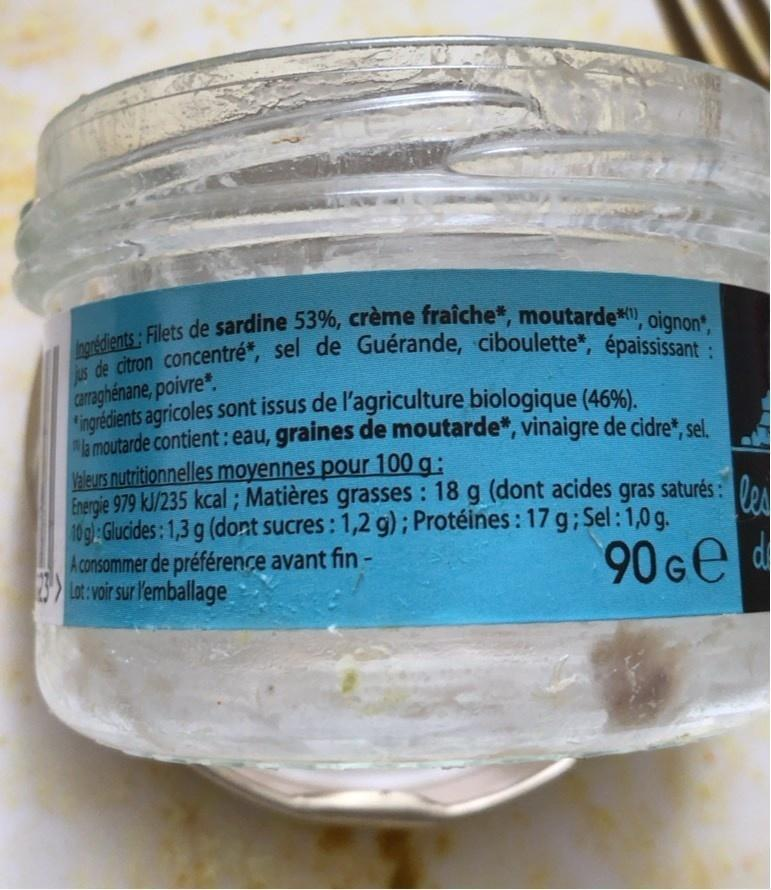

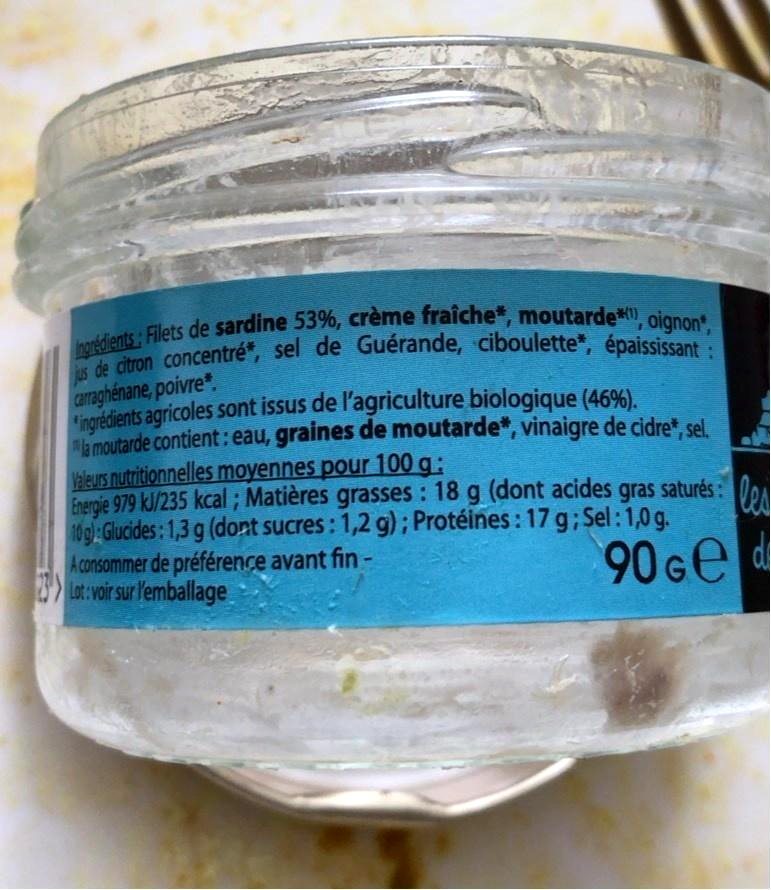

test:1 Pixel proxies only; no evidence of improved OCR accuracy. Need matched manual transcription and controlled OCR experiment before adoption.


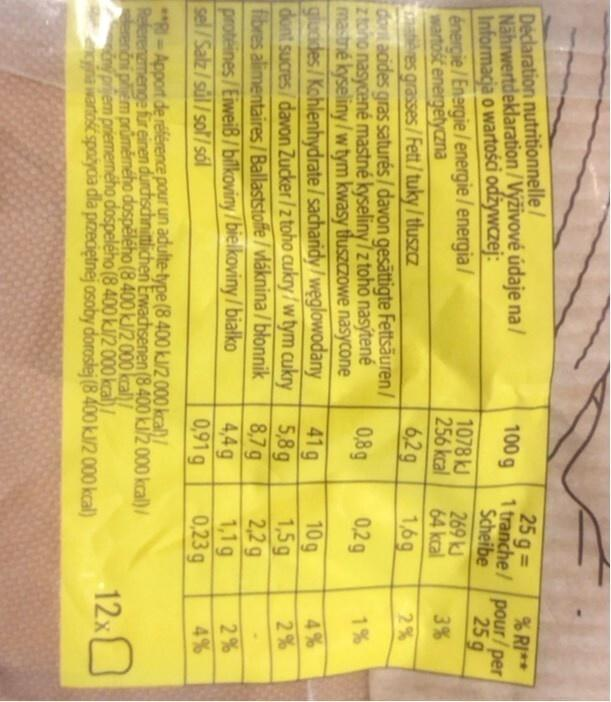

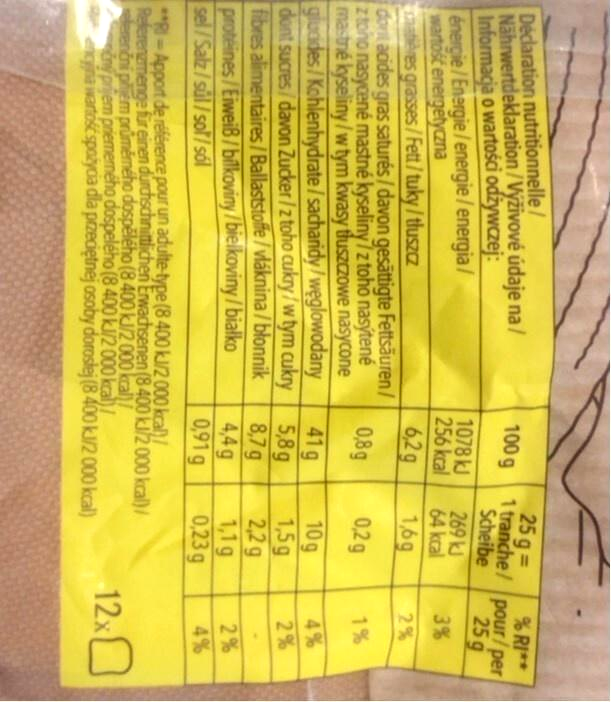

,Observed issue,Number affected,denominator,% affected,denominator_scope,decision_class,Preprocessing required,Expected benefit,Validation method
0,Input longer than 512 LayoutLMv3 subwords incl...,455,3083,14.758352,tokenizer-measured annotated images,Required preprocessing,Retain existing overlapping sliding windows an...,Full original-word coverage rather than silent...,Assert every original word is covered; validat...
1,Invalid/alignment-risk token-box-label records,47,3083,1.524489,all annotated images,Required preprocessing,"Validate aligned tokens/boxes/labels and [0,10...",Prevent invalid model inputs while preserving ...,"Read-only alignment, coordinate and tokenizer ..."
2,EXIF orientation transformation indicated,0,25,0.000000,cached pixel-measured images only,Required preprocessing,Retain EXIF-aware image loading for new OCR in...,Avoid metadata-directed orientation mismatch.,Compare original/oriented dimensions and trans...
3,Short image side below 400 pixels,327,3083,10.606552,all images with source dimensions,Data-quality review flag,Inspect legibility; do not assume upscaling re...,Identify likely text-detail limitations before...,Inspect representative panels and validate OCR...
4,Source maximum side exceeds existing 2000px OC...,541,3083,17.547843,all images with source dimensions,Optional preprocessing,Retain aspect-preserving maximum-side resize a...,Bound CPU OCR workload while avoiding unnecess...,Compare before/after legibility and manual-ref...
5,Low grayscale contrast proxy,3,25,12.000000,cached pixel-measured convenience sample only,Optional preprocessing,Consider contrast normalization only on review...,Potential readability benefit is a hypothesis;...,Paired before/after OCR on manually transcribe...
6,Low sharpness/Laplacian proxy,0,25,0.000000,cached pixel-measured convenience sample only,Optional preprocessing,Review small/blurred panels; do not apply unco...,Potential readability benefit is a hypothesis;...,Paired before/after OCR on manually transcribe...
7,Dark luminance proxy,1,25,4.000000,cached pixel-measured convenience sample only,Optional preprocessing,Consider brightness correction only if visual ...,Potential readability benefit is a hypothesis;...,Paired before/after OCR on manually transcribe...
8,Bright luminance proxy,0,25,0.000000,cached pixel-measured convenience sample only,Optional preprocessing,Review white-background versus overexposure; a...,Potential readability benefit is a hypothesis;...,Paired before/after OCR on manually transcribe...
9,Small OCR envelope within image (<40% of norma...,96,3083,3.113850,all annotated images with valid boxes,Data-quality review flag,Inspect candidate margins; do not auto-crop fr...,Potentially reduce irrelevant packaging text w...,Manually verify crop retains every target span...


No OCR or model benefit is claimed from pixel proxies. Original cached image hashes are validated unchanged.


In [11]:
display(tables['proxy_experiments'])
for item in pixels.sort_values(['quality_flags','image_key'], ascending=[False,True]).head(4).to_dict('records'):
    print(item['image_key'], item['barcode'], item['quality_flags'] or 'No threshold flag; not a quality certificate')
    display(DisplayImage(filename=item['local_image_path'], width=500))
for item in tables['proxy_experiments'].head(2).to_dict('records'):
    print(item['image_key'], item['conclusion'])
    display(DisplayImage(filename=item['original_path'], width=400))
    display(DisplayImage(filename=item['transformed_path'], width=400))
display(recommendations.rename(columns={'observed_issue':'Observed issue','affected_count':'Number affected','affected_percent':'% affected','preprocessing_required':'Preprocessing required','expected_benefit':'Expected benefit','validation_method':'Validation method'}))
print('No OCR or model benefit is claimed from pixel proxies. Original cached image hashes are validated unchanged.')

## 5. Final validation

Validate unchanged source Parquet, original cached images, prior notebooks and preprocessing implementations; check the all-image and cached-pixel denominators, the official splits, tokenizer-only length coverage and recommendations. This notebook does not import/read cached predictions or modify gold. The dashboard reads only these small saved readiness artifacts, with supported split/nutrient/country/quality filters. All existing model-performance analyses remain separately accessible under **Post-Inference Diagnostics**.

In [12]:
import subprocess
for filename, expected_hash in manifest['source_sha256'].items():
    assert readiness.sha(filename) == expected_hash, f'Protected input changed externally: {filename}'
for filename, expected_hash in manifest['measured_image_sha256'].items():
    assert readiness.sha(filename) == expected_hash, f'Original image changed: {filename}'
assert len(tables['images']) == 3083
assert tables['images']['image_key'].is_unique
assert tables['images'].groupby('split').size().to_dict() == {'train':2884,'test':199}
assert manifest['token_annotations'] == 309190
assert manifest['tokenizer_measured_images'] == 3083
assert manifest['pixel_measured_images'] == len(pixels)
assert manifest['sliding_window_images'] == int(tables['images']['needs_sliding_window'].sum())
assert manifest['prediction_caches_read'] == manifest['model_inference_runs'] == manifest['ocr_runs'] == 0
assert not {'f1','precision','recall','predicted_labels'} & set(tables['images'])
assert recommendations['affected_count'].le(recommendations['denominator']).all()
assert tables['proxy_experiments']['ocr_quality_before'].isna().all()
checks = subprocess.run([sys.executable,'-m','pytest','-q',str(ROOT / 'tests')], cwd=ROOT, capture_output=True, text=True)
print(checks.stdout)
if checks.returncode:
    print(checks.stderr)
    raise RuntimeError('Regression tests failed.')
print('Readiness validated. No predictions/model/OCR runs, no original image/gold edits; preprocessing proxy copies saved separately.')

........................................................................ [ 81%]
................                                                         [100%]
88 passed in 2.63s

Readiness validated. No predictions/model/OCR runs, no original image/gold edits; preprocessing proxy copies saved separately.


## Decision summary

- **Required input capabilities:** retain overlapping windows for **455/3,083 (14.76%)** overlength records, original `word_ids` mapping, and independent geometry/alignment checks. The **47 (1.52%)** geometry-review records contain zero-area boxes; this is not evidence that their token arrays are misaligned. Supplied coordinates are already normalized—do not normalize again.
- **Parser readiness, not pixel or gold rewriting:** decimal commas occur on **2,463/3,083 (79.89%)** images and merged number/unit strings on **2,565 (83.20%)**. These justify locale/unit-aware downstream parsing while preserving raw OCR words and boxes.
- **Optional image operations:** **541/3,083 (17.55%)** sources exceed the existing 2,000px cap; aspect-preserving downscaling is a CPU-resource trade-off, not established accuracy improvement. Low contrast **3/25 (12%)** and dark luminance **1/25 (4%)** concern only the cached convenience sample. Eight copy-only experiments establish pixel changes, not OCR benefit.
- **Orientation caveat:** the displayed **test:1** panel is visibly sideways despite no EXIF transformation flag. Thus **0/25 EXIF flags does not mean 25 upright images**. Review text orientation before new-image OCR; any rotation of annotated images must remap boxes and retain provenance. No reliable full-inventory text-rotation rate was measured.
- **Review, not automatic correction:** **327 (10.61%)** short-side flags, **96 (3.11%)** small OCR envelopes, **890 (28.87%)** multi-number-token flags and **386 (12.52%)** glyph/separator flags. Backward-y jumps on **2,825 (91.63%)** images can reflect valid multi-column layouts, not incorrect reading order.
- **Metadata safety:** serving context is missing on **2,339/3,075 (76.07%)** matched products. Keep per-serving/per-100g bases separate. Eleven products have quantity-review flags under the mapped-nutrient rules; metadata is not visual gold. All eight unmatched images remain included.

No unconditional enhancement, automatic crop, token reordering, glyph replacement or gold repair is justified by these screens. Validate candidate image operations with paired OCR against independent manual transcription before adopting them; do not tune them using official-test model errors.